# WER Challenge

# Vorwort

Auf dieser Open Mini Challenge haben sich Michaela Brutenic, Roberto Fazekas und Emircan Bagcivan beteiligt.

# Einleitung
Die vorliegende Open Mini Challenge hat als Ziel die Entwicklung eines Wahrscheinlichkeitsmodells, das vorhersagt, ob es am nächsten Tag in Basel regnen wird. Grundlage für die Modellierung bilden regionale Wetterdaten aus den Jahren 2020 bis 2025, die eine Vielzahl meteorologischer Merkmale wie Temperatur, Luftfeuchtigkeit, Luftdruck, Windverhältnisse und Niederschlagsmengen enthalten.

Ziel ist es, auf Basis dieser Daten mithilfe klassischer Methoden der Wahrscheinlichkeitsrechnung – wie etwa bedingter Wahrscheinlichkeiten, Häufigkeitsverteilungen, Übergangswahrscheinlichkeiten oder auch einfacher stochastischer Modelle – ein mathematisches Modell zu konstruieren, dass die Regenwahrscheinlichkeit für den folge Tag beschreibt.

Die vollständige Datenlage erlaubt dabei eine fundierte Analyse, um die Abhängigkeiten zwischen Wettermerkmalen und Regenereignissen zu untersuchen. Das Modell soll dabei nicht nur eine Ja/Nein-Aussage treffen,  [sondern explizit die Wahrscheinlichkeit eines Regenereignisses angeben.]  Es bietet somit einen praktischen Anwendungsfall für stochastische Denkweisen im realweltlichen Kontext der Wettervorhersage.

Die Daten liegen in strukturierter Form vor und ermöglichen sowohl eine fundierte explorative Analyse als auch die Anwendung klassischer Verfahren der Wahrscheinlichkeitsrechnung. Ziel ist es, ein robustes, nachvollziehbares Modell zu entwickeln, das verlässliche Aussagen zur Regenwahrscheinlichkeit liefert 

# Definition der Fragestellung
Im Zentrum dieser Arbeit steht die folgende Fragestellung:

Wie lässt sich auf Grundlage historischer Wetterdaten die Wahrscheinlichkeit eines Regenereignisses für den folgenden Tag in Basel mathematisch modellieren?

Dabei sollen insbesondere stochastische Zusammenhänge zwischen verschiedenen meteorologischen Einflussgrößen und dem Auftreten von Regenereignissen identifiziert und in ein Wahrscheinlichkeitsmodell überführt werden. Das Ziel besteht darin, ein Modell zu entwickeln, das auf klar definierten, datenbasierten Regeln beruht und eine quantifizierte Vorhersage zur Regenwahrscheinlichkeit erlaubt – anstelle einer binären Entscheidung.

# Hypothese


# Lösungsstrategie

# Systemdefinition

# Wahrscheinlichkeitsmodell

# Abhängigkeiten und Unsicherheiten

# Erweiterung durch neue Erkenntnisse

### Imports

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

## Einlesen von Dateien und kombinieren

In [16]:
df_2020 = pd.read_csv('data/wetterdaten_2020.csv', sep=';')
df_2021 = pd.read_csv('data/wetterdaten_2021.csv', sep=';')
df_2022 = pd.read_csv('data/wetterdaten_2022.csv', sep=';')
df_2023 = pd.read_csv('data/wetterdaten_2023.csv', sep=';')
df_2024 = pd.read_csv('data/wetterdaten_2024.csv', sep=';')
df_2025 = pd.read_csv('data/wetterdaten_2025.csv', sep=';')

print(df_2020.columns)


df_2020_2025_merged = pd.concat([
    df_2020,
    df_2021,
    df_2022,
    df_2023,
    df_2024,
    df_2025
], ignore_index=True)

Index(['Datum', 'Jahr', 'Globalstrahlung in W/m2', 'Gesamtschneemenge',
       'Gesamtbewölkung', 'Luftdruck in hPa', 'Niederschlag',
       'Sonnenscheindauer', 'Tagesmittel Lufttemperatur',
       'Tagesminimum Lufttemperatur', 'Tagesmaximum Lufttemperatur',
       'Relative Luftfeuchtigkeit'],
      dtype='object')


## Korrelations Plot

Damit wir die Auswahl der Variablen fundiert treffen können untersuchen wir die Korrelationen der einzelnen
Beobachtungen. Unsere Wahl fällt dann auf die Beobachtung welche einerseits die höchste Korrelation zum
Niederschlag hat, sowie auf die Beobachtung welche aus meteorologischer Sicht Sinn macht.

In [18]:
# Zusammenfügen der Daten über die letzten fünf Jahre
df_2020_2025_merged = df_2020_2025_merged[[
    'Globalstrahlung in W/m2',
    'Gesamtschneemenge',
    'Gesamtbewölkung',
    'Luftdruck in hPa',
    'Niederschlag',
    'Sonnenscheindauer',
    'Tagesmittel Lufttemperatur',
    'Tagesminimum Lufttemperatur',
    'Tagesmaximum Lufttemperatur',
    'Relative Luftfeuchtigkeit'
]]

# Korrelationen erkennen
df_correlation = df_2020_2025_merged.corr()
df_correlation.style.background_gradient(cmap='coolwarm')

,Globalstrahlung in W/m2,Gesamtschneemenge,Gesamtbewölkung,Luftdruck in hPa,Niederschlag,Sonnenscheindauer,Tagesmittel Lufttemperatur,Tagesminimum Lufttemperatur,Tagesmaximum Lufttemperatur,Relative Luftfeuchtigkeit
Globalstrahlung in W/m2,1.000000,-0.123481,-0.612242,0.075762,-0.184369,0.876576,0.719938,0.550995,0.784065,-0.725688
Gesamtschneemenge,-0.123481,1.000000,0.069145,0.006758,-0.020547,-0.097889,-0.222621,-0.228159,-0.224008,0.078526
Gesamtbewölkung,-0.612242,0.069145,1.000000,-0.322901,0.306266,-0.831492,-0.247045,-0.061028,-0.357601,0.535739
Luftdruck in hPa,0.075762,0.006758,-0.322901,1.000000,-0.327941,0.224670,-0.135541,-0.191338,-0.088855,-0.035223
Niederschlag,-0.184369,-0.020547,0.306266,-0.327941,1.000000,-0.273878,0.064861,0.137679,0.034233,0.264342
Sonnenscheindauer,0.876576,-0.097889,-0.831492,0.224670,-0.273878,1.000000,0.507379,0.299324,0.610960,-0.702985
Tagesmittel Lufttemperatur,0.719938,-0.222621,-0.247045,-0.135541,0.064861,0.507379,1.000000,0.955118,0.978960,-0.444893
Tagesminimum Lufttemperatur,0.550995,-0.228159,-0.061028,-0.191338,0.137679,0.299324,0.955118,1.000000,0.890151,-0.242812
Tagesmaximum Lufttemperatur,0.784065,-0.224008,-0.357601,-0.088855,0.034233,0.610960,0.978960,0.890151,1.000000,-0.528576
Relative Luftfeuchtigkeit,-0.725688,0.078526,0.535739,-0.035223,0.264342,-0.702985,-0.444893,-0.242812,-0.528576,1.000000


## Analyse der Korrelationen
Damit wir nicht auf eine unübersichtliche Matrix schauen müssen ordnen wir die Werte der Korrelation der Grösse nach und
veranschaulichen die Werte in einem Barplot.

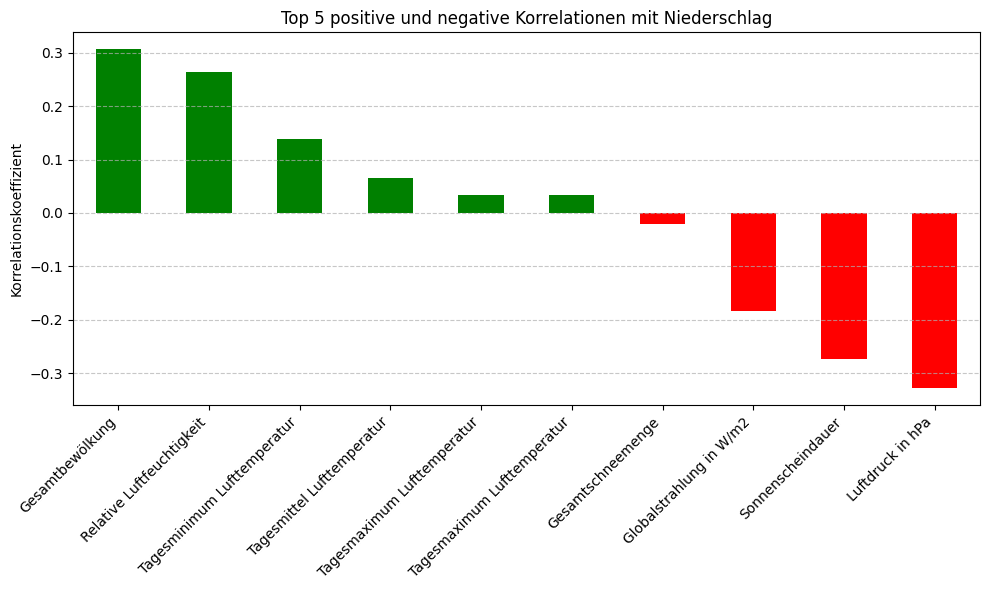

In [19]:
# Höchste wie tiefste Korrelationen
df_correlation_highest = (df_correlation["Niederschlag"].drop("Niederschlag")
                          .sort_values(ascending=False)).head(5)
df_correlation_lowes = (df_correlation["Niederschlag"]
                        .drop("Niederschlag").sort_values(ascending=True)).head(5)

combined_corr = (pd.concat([df_correlation_highest, df_correlation_lowes])
                 .sort_values(ascending=False))

plt.figure(figsize=(10, 6))
combined_corr.plot(kind='bar', color=['green' if corr > 0 else 'red' for corr in combined_corr.values])
plt.title("Top 5 positive und negative Korrelationen mit Niederschlag")
plt.ylabel("Korrelationskoeffizient")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()